# Modularity on the Karate Club Graph
## DSC212: Graph Theory - Research Assignment

**Student:** Shashwat Sangwan  
**Method:** recursive spectral modularity bisection, implemented with NumPy  
**Dataset:** Zachary's Karate Club, via NetworkX  
**Repository:** [shashwat25-dot/DSC-212](https://github.com/shashwat25-dot/DSC-212)

This notebook detects communities, draws the complete partition after every accepted
split, computes four node metrics after each split, plots every node's metric history,
and discusses the computed results. Code, explanations, figures, and outputs are included.

**Run:** use Python 3.12, install `requirements.txt`, open this notebook, and select
**Restart Kernel and Run All Cells**. No manual data download, absolute file paths,
or edits to the notebook are needed. The final cells regenerate `artifacts/`.

**AI assistance:** this notebook was prepared with AI assistance, as permitted in the
course announcement. The algorithms, assumptions, numerical checks, and interpretations
are exposed below so the work can be reproduced and studied.

## 1. Question, deliverables, and explicit conventions

Can friendship structure reveal communities, and how do nodes' roles differ between
the full club and their own communities? Historical faction labels are used only for
an optional comparison after detection, never as inputs to the detector.

| Requirement | Where it is met |
|---|---|
| Implement recursive spectral modularity partitioning | Sections 3-4; no built-in community detector |
| Draw graph after every split | Section 5; fixed coordinates, colored communities, node IDs |
| Compute degree, betweenness, closeness, clustering for every node | Section 6 |
| Store iteration dictionaries and plot every node's evolution | Sections 6-7 |
| Discuss persistent centrality and community effects | Section 8 |
| Runnable notebook and required citation | All cells; references in Section 11 |

**Conventions that affect the answer**

- The graph is **simple, undirected, and unweighted**, matching the binary adjacency
  matrix in the handout. NetworkX's original edge weights are deliberately discarded.
- Node IDs are NetworkX's **0-33**, not the original paper's 1-34.
- One **iteration is one accepted split**; iteration 0 is the unsplit baseline.
- Recursion is depth first, visiting the child containing the smallest node first.
  Community IDs record the split tree (`C`, `C0`, `C1`, `C00`, ...).
- **Community detection always scores the original graph.** Original degrees and the
  original number of edges remain fixed throughout recursion.
- The primary metric histories describe **each node inside its current community's
  induced subgraph**. The full-graph metrics are also recorded at every iteration as
  a control: assigning colors alone cannot change them.

**Clarification of the recursive formula.** The handout's pages 5 and 9-10 describe
an unadjusted block of the global modularity matrix, while page 6 mentions recomputing
on an induced subgraph. To optimize one consistent global modularity objective, this
notebook follows the corrected community matrix in Newman (2006). It also verifies
the actual gain after rounding, rather than treating a positive eigenvalue as a guarantee.
The correction and its derivation are shown next; it is not a hidden change of method.

**Clarification of metric evolution.** The handout does not specify which graph should
be passed to the metric functions after partitioning. Within-community metrics are a
documented interpretation, not a claim that the original friendships physically changed.
They measure local roles; full-graph results provide the corresponding global context.

In [1]:
%matplotlib inline
from pathlib import Path
from itertools import product
import importlib.metadata
import json
import math
import platform

import numpy as np
import networkx as nx
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display, Markdown

SEED = 212
TOLERANCE = 1e-10
ARTIFACTS = Path("artifacts")
FIGURES = ARTIFACTS / "figures"
TABLES = ARTIFACTS / "tables"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160,
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.titlesize": 13, "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.grid": False,
    "figure.facecolor": "white", "axes.facecolor": "white",
})
versions = {name: importlib.metadata.version(name) for name in
            ["numpy", "networkx", "pandas", "matplotlib", "nbformat", "nbclient", "ipykernel", "nbconvert"]}
print("Python:", platform.python_version())
display(pd.DataFrame(versions.items(), columns=["Package", "Version"]))

Python: 3.12.14


,Package,Version
0,numpy,2.5.5
1,networkx,3.7
2,pandas,3.1.1
3,matplotlib,3.11.2
4,nbformat,5.11.1
5,nbclient,0.11.0
6,ipykernel,7.4.0
7,nbconvert,7.17.2


## 2. Dataset and initial inspection

Each vertex represents a club member; an edge represents an observed relationship.
The network contains 34 nodes and 78 edges. Its small size lets us inspect every split.
The recorded `club` attribute provides the two historical factions, but a recursive
modularity method is free to find more than two communities.

The adjacency matrix must use a fixed node order. Otherwise an eigenvector's position
could be mistaken for the wrong node ID. Reusing one layout also prevents apparent
movement from being confused with changes of community.

In [2]:
source_graph = nx.karate_club_graph()
G = nx.Graph()
G.add_nodes_from((node, dict(data)) for node, data in source_graph.nodes(data=True))
G.add_edges_from(source_graph.edges())  # Explicitly omit original weight attributes.
NODES = tuple(sorted(G.nodes()))
NODE_INDEX = {node: position for position, node in enumerate(NODES)}
ORIGINAL_EDGES = frozenset(frozenset(edge) for edge in G.edges())
assert len(NODES) == 34 and G.number_of_edges() == 78
assert all("weight" not in data for _, _, data in G.edges(data=True))
POSITIONS = nx.spring_layout(G, seed=SEED, weight=None, k=0.45, iterations=200)
# A small deterministic spacing pass prevents overlapping node markers. The
# resulting spring-based coordinates are then reused for EVERY partition.
MIN_NODE_SPACING = 0.13
for _ in range(20):
    for left, node_a in enumerate(NODES):
        for node_b in NODES[left + 1:]:
            difference = POSITIONS[node_a] - POSITIONS[node_b]
            distance = np.linalg.norm(difference)
            if 0 < distance < MIN_NODE_SPACING:
                shift = 0.5 * (MIN_NODE_SPACING - distance) * difference / distance
                POSITIONS[node_a] += shift
                POSITIONS[node_b] -= shift

display(pd.DataFrame([{
    "nodes": len(G), "edges": G.number_of_edges(),
    "connected": nx.is_connected(G), "density": nx.density(G),
    "total_degree": sum(dict(G.degree()).values()),
}]))
node_information = pd.DataFrame([{
    "node": node, "degree": G.degree(node), "historical_faction": G.nodes[node]["club"]
} for node in NODES])
display(node_information.head(10))

,nodes,edges,connected,density,total_degree
0,34,78,True,0.139037,156


,node,degree,historical_faction
0,0,16,Mr. Hi
1,1,9,Mr. Hi
2,2,10,Mr. Hi
3,3,6,Mr. Hi
4,4,3,Mr. Hi
5,5,4,Mr. Hi
6,6,4,Mr. Hi
7,7,4,Mr. Hi
8,8,5,Mr. Hi
9,9,2,Officer


## 3. Mathematics of the method

For an undirected unweighted graph, $A$ is its adjacency matrix, $k_i$ is the original
degree of node $i$, and $m$ is the original edge count. The modularity matrix is

$$B=A-\frac{kk^\top}{2m}.$$

An entry compares an observed edge with the degree-based null-model baseline.
$B_{ij}>0$ favors assigning the pair together; it does not assert their membership.
A negative entry is a penalty, not a prohibition. Modularity balances all pair contributions.
It is a quality score, not by itself a statistical significance test.

For an arbitrary partition $\mathcal P$,

$$Q(\mathcal P)=\frac1{2m}\sum_{C\in\mathcal P}\sum_{i,j\in C}B_{ij}.$$

For just two groups, encode membership by $s_i\in\{-1,+1\}$. Since the same-group
indicator is $(1+s_is_j)/2$ and $B\mathbf1=0$,

$$Q=\frac1{4m}s^\top Bs.$$

**Why a leading eigenvector?** Searching all binary assignments is expensive. A binary
vector has $\|s\|^2=n$. Relax its entries to real values while keeping this norm. Write
$s=\sum_r\alpha_r u_r$ in an orthonormal eigenbasis of the real symmetric matrix $B$.
Then $s^\top Bs=\sum_r\lambda_r\alpha_r^2\le n\lambda_{\max}$.
The relaxed optimum points along the leading eigenvector. Using a unit vector instead
changes the scale, not the maximizing direction. Taking signs returns a candidate binary
partition, which must be evaluated: rounding is not guaranteed to find the discrete optimum.

### Correct gain for subdividing an existing community

Let $B_C=B[C,C]$, retaining the original degrees and $m$. Before subdivision, all pairs
inside $C$ contribute. After subdivision, only pairs assigned to the same child contribute.
Their difference is

$$\Delta Q=\frac1{4m}\left(s^\top B_Cs-\mathbf1^\top B_C\mathbf1\right).$$

Because $s_i^2=1$, define

$$\widetilde B_C=B_C-\operatorname{diag}(B_C\mathbf1),\qquad
\Delta Q=\frac1{4m}s^\top\widetilde B_Cs.$$

This is Newman's generalized community matrix. The diagonal adjustment subtracts the
pre-split contribution and makes the no-split gain zero. A raw block need not have zero
row sums, so using $s^\top B_Cs/(4m)$ alone is not the gain.
See [Newman (2006), multi-community section](https://doi.org/10.1073/pnas.0601602103)
and the [accessible author preprint](https://arxiv.org/html/physics/0602124).

**Decision rule:** stop if the adjusted matrix has no positive eigenvalue within numerical
tolerance. Otherwise form the sign split and accept it only if both children are nonempty
and the verified gain exceeds the tolerance. Rejecting one rounded proposal does not prove
that every possible binary partition fails. No fine-tuning or built-in detector is used.

## 4. Implementation and numerical checks

The following functions construct $B$, score a complete partition, and implement
recursive bisection. A snapshot is an independent copy of the current partition, so
later recursive calls cannot overwrite earlier history.

`numpy.linalg.eigh` is appropriate because the matrices are real and symmetric. Its
eigenvalues are returned in ascending order, so the last eigenvector corresponds to the
largest algebraic eigenvalue. An arbitrary overall eigenvector sign is normalized for
diagnostics; child names are ordered by node ID, independent of that sign.

In [3]:
def build_modularity_matrix(graph):
    """Use one node order and an unweighted, undirected, simple graph."""
    if graph.is_directed() or graph.is_multigraph() or nx.number_of_selfloops(graph):
        raise ValueError("This implementation expects a simple undirected graph without loops.")
    nodes = tuple(sorted(graph.nodes()))
    if not nodes:
        raise ValueError("The graph must contain at least one node.")
    adjacency = nx.to_numpy_array(graph, nodelist=nodes, weight=None, dtype=float)
    degree = adjacency.sum(axis=1)
    edges = graph.number_of_edges()
    # The edgeless case is handled separately: there is no modularity denominator.
    matrix = (adjacency - np.outer(degree, degree) / (2 * edges)
              if edges else np.zeros_like(adjacency))
    return nodes, adjacency, degree, edges, matrix


def modularity_from_matrix(matrix, partition, node_index, edges):
    """Score any number of communities against the ORIGINAL graph's null model."""
    if edges == 0:
        return 0.0  # Explicit implementation convention for an edgeless graph.
    total = 0.0
    for group in partition.values():
        indices = [node_index[node] for node in group]
        total += matrix[np.ix_(indices, indices)].sum()
    value = float(total / (2 * edges))
    return 0.0 if abs(value) < 1e-14 else value  # Remove numerical negative zero.


def recursive_spectral_modularity(graph, tolerance=1e-10):
    """Recursive sign-based spectral bisection; no built-in community detector.

    The original B, degrees, and m remain fixed throughout. Each accepted split
    produces a complete partition snapshot. Recursion visits the child with the
    smallest node first. Children are identified by tree paths C0, C1, etc.
    """
    nodes, adjacency, degree, edges, matrix = build_modularity_matrix(graph)
    node_index = {node: index for index, node in enumerate(nodes)}
    partition = {"C": nodes}
    attempts = []
    history = []

    def score(groups):
        return modularity_from_matrix(matrix, groups, node_index, edges)

    def save_snapshot(parent=None, children=None, gain=0.0, leading=None):
        snapshot = {key: tuple(group) for key, group in sorted(partition.items())}
        history.append({
            "iteration": len(history),
            "partition": snapshot,
            "modularity": score(snapshot),
            "split_parent": parent,
            "split_children": children,
            "gain": float(gain),
            "leading_eigenvalue": leading,
        })

    def visit(community_id):
        group = partition[community_id]
        record = {"community": community_id, "nodes": list(group),
                  "size": len(group), "accepted": False,
                  "leading_eigenvalue": None, "candidate_gain": None,
                  "eigenvalue_gap": None, "reason": None}
        if len(group) < 2 or edges == 0:
            record["reason"] = "singleton" if len(group) < 2 else "edgeless graph"
            attempts.append(record)
            return

        indices = [node_index[node] for node in group]
        block = matrix[np.ix_(indices, indices)]
        # Newman community matrix: subtract the row sums on the diagonal.
        adjusted = block - np.diag(block.sum(axis=1))
        assert np.allclose(adjusted.sum(axis=1), 0.0, atol=1e-9)
        eigenvalues, eigenvectors = np.linalg.eigh(adjusted)
        leading = float(eigenvalues[-1])  # Largest algebraic eigenvalue.
        vector = eigenvectors[:, -1].copy()
        # Fix the otherwise arbitrary overall sign for readable diagnostics.
        if vector[np.argmax(np.abs(vector))] < 0:
            vector *= -1
        record["leading_eigenvalue"] = leading
        record["eigenvalue_gap"] = float(eigenvalues[-1] - eigenvalues[-2])
        if leading <= tolerance:
            record["reason"] = "no positive leading eigenvalue within tolerance"
            attempts.append(record)
            return

        signs = np.where(vector > 0.0, 1.0, -1.0)
        positive = tuple(group[i] for i in range(len(group)) if signs[i] > 0)
        negative = tuple(group[i] for i in range(len(group)) if signs[i] < 0)
        if not positive or not negative:
            record["reason"] = "candidate has an empty child"
            attempts.append(record)
            return

        # Canonical child names do not depend on the eigenvector's overall sign.
        child_groups = sorted([positive, negative], key=lambda child: child[0])
        child_ids = (community_id + "0", community_id + "1")
        candidate = dict(partition)
        del candidate[community_id]
        candidate.update(dict(zip(child_ids, child_groups)))
        predicted_gain = float(signs @ adjusted @ signs / (4 * edges))
        actual_gain = score(candidate) - score(partition)
        assert np.isclose(predicted_gain, actual_gain, atol=1e-10)
        record["candidate_gain"] = actual_gain
        record["quadratic_gain"] = predicted_gain
        record["children"] = {key: list(child) for key, child in zip(child_ids, child_groups)}
        if actual_gain <= tolerance:
            record["reason"] = "rounded sign proposal has no positive modularity gain"
            attempts.append(record)
            return

        record["accepted"] = True
        record["reason"] = "positive gain verified against the complete partition"
        attempts.append(record)
        partition.clear()
        partition.update(candidate)
        save_snapshot(community_id, child_ids, actual_gain, leading)
        visit(child_ids[0])
        visit(child_ids[1])

    save_snapshot()  # Iteration 0: everyone in one community.
    visit("C")
    return {"nodes": nodes, "adjacency": adjacency, "degree": degree,
            "edges": edges, "matrix": matrix, "node_index": node_index,
            "history": history, "attempts": attempts,
            "communities": dict(sorted(partition.items()))}

In [4]:
result = recursive_spectral_modularity(G, tolerance=TOLERANCE)
B = result["matrix"]
history = result["history"]
attempts = result["attempts"]
final_partition = result["communities"]
m = result["edges"]

assert np.allclose(B, B.T)
assert np.allclose(B.sum(axis=1), 0.0, atol=1e-10)
assert sum(result["degree"]) == 2 * m

summary = pd.DataFrame([{
    "iteration": state["iteration"],
    "split_parent": state["split_parent"] or "baseline",
    "communities": len(state["partition"]),
    "sizes": ", ".join(str(len(group)) for group in state["partition"].values()),
    "modularity": state["modularity"],
    "gain": state["gain"],
    "leading_eigenvalue": state["leading_eigenvalue"],
} for state in history])
print("Each row is a complete partition after one accepted split.")
display(summary.round(6))
print("All candidate tests, including rejected proposals:")
attempt_table = pd.DataFrame([{key: row.get(key) for key in
    ["community", "size", "leading_eigenvalue", "candidate_gain", "accepted", "reason"]}
    for row in attempts])
display(attempt_table.round(6))

Each row is a complete partition after one accepted split.


,iteration,split_parent,communities,sizes,modularity,gain,leading_eigenvalue
0,0,baseline,1,34,0.000000,0.000000,NaN
1,1,C,2,"16, 18",0.371466,0.371466,4.977080
2,2,C0,3,"7, 9, 18",0.372699,0.001233,1.178538
3,3,C1,4,"7, 9, 12, 6",0.393409,0.020710,0.859415


All candidate tests, including rejected proposals:


,community,size,leading_eigenvalue,candidate_gain,accepted,reason
0,C,34,4.977080,0.371466,True,positive gain verified against the complete pa...
1,C0,16,1.178538,0.001233,True,positive gain verified against the complete pa...
2,C00,7,0.000000,NaN,False,no positive leading eigenvalue within tolerance
3,C01,9,0.060191,-0.015779,False,rounded sign proposal has no positive modulari...
4,C1,18,0.859415,0.020710,True,positive gain verified against the complete pa...
5,C10,12,-0.000000,NaN,False,no positive leading eigenvalue within tolerance
6,C11,6,0.000000,NaN,False,no positive leading eigenvalue within tolerance


In [5]:
# Independent validation of all snapshots against NetworkX's score function.
# It is used to CHECK modularity, not to discover communities.
for state in history:
    groups = list(state["partition"].values())
    flattened = [node for group in groups for node in group]
    assert sorted(flattened) == list(NODES) and len(set(flattened)) == len(NODES)
    assert all(len(group) > 0 for group in groups)
    expected = nx.community.modularity(G, [set(group) for group in groups], weight=None)
    assert np.isclose(state["modularity"], expected, atol=1e-10)
for previous, current in zip(history, history[1:]):
    assert current["modularity"] - previous["modularity"] > TOLERANCE
    assert np.isclose(current["gain"], current["modularity"] - previous["modularity"])
    assert len(current["partition"]) == len(previous["partition"]) + 1
    parent = set(previous["partition"][current["split_parent"]])
    child_a, child_b = (set(current["partition"][key]) for key in current["split_children"])
    assert not child_a.intersection(child_b) and child_a.union(child_b) == parent
assert frozenset(frozenset(edge) for edge in G.edges()) == ORIGINAL_EDGES

# A complete graph should have no beneficial community split.
clique_result = recursive_spectral_modularity(nx.complete_graph(5))
assert len(clique_result["history"]) == 1

# Two triangles connected by one edge provide a small positive-gain example.
toy = nx.Graph([(0, 1), (1, 2), (2, 0), (3, 4), (4, 5), (5, 3), (2, 3)])
toy_result = recursive_spectral_modularity(toy)
assert len(toy_result["history"]) > 1
assert toy_result["history"][-1]["modularity"] > 0

# Test the recursive gain identity for EVERY sign vector of a proper toy subset.
subset = (0, 1, 2)
indices = [toy_result["node_index"][node] for node in subset]
block = toy_result["matrix"][np.ix_(indices, indices)]
adjusted = block - np.diag(block.sum(axis=1))
before_partition = {"test": subset, "rest": (3, 4, 5)}
before_q = nx.community.modularity(toy, list(before_partition.values()), weight=None)
gain_cases = 0
for pattern in product([-1, 1], repeat=len(subset)):
    signs = np.asarray(pattern, dtype=float)
    proposed = [tuple(node for node, sign in zip(subset, signs) if sign == side)
                for side in [-1, 1]]
    proposed = [group for group in proposed if group] + [(3, 4, 5)]
    actual = nx.community.modularity(toy, proposed, weight=None) - before_q
    predicted = float(signs @ adjusted @ signs / (4 * toy.number_of_edges()))
    assert np.isclose(predicted, actual, atol=1e-10)
    gain_cases += 1
assert np.isclose(np.ones(3) @ adjusted @ np.ones(3), 0.0)

# An edgeless graph and a singleton terminate cleanly under the stated convention.
assert len(recursive_spectral_modularity(nx.empty_graph(3))["history"]) == 1
assert len(recursive_spectral_modularity(nx.empty_graph(1))["history"]) == 1
print(f"Passed: all partition, gain, node-coverage, and graph-preservation checks; {gain_cases} toy gain cases.")

Passed: all partition, gain, node-coverage, and graph-preservation checks; 8 toy gain cases.


### First eigenvector, inspected directly

This table connects matrix positions to node IDs. Magnitudes indicate strength in this
relaxed direction, not calibrated membership probabilities. Small entries are near the
sign boundary. Reversing every sign only exchanges the two child names.

In [6]:
root_eigenvalues, root_eigenvectors = np.linalg.eigh(B)
root_vector = root_eigenvectors[:, -1].copy()
if root_vector[np.argmax(np.abs(root_vector))] < 0:
    root_vector *= -1
first_partition = history[1]["partition"] if len(history) > 1 else history[0]["partition"]
first_membership = {node: key for key, group in first_partition.items() for node in group}
first_split_details = pd.DataFrame({
    "node": NODES,
    "eigenvector_entry": root_vector,
    "community_after_first_split": [first_membership[node] for node in NODES],
})
display(first_split_details.round(6))

,node,eigenvector_entry,community_after_first_split
0,0,0.387543,C0
1,1,0.269557,C0
2,2,0.131899,C0
3,3,0.253452,C0
4,4,0.134003,C0
5,5,0.145738,C0
6,6,0.145738,C0
7,7,0.209360,C0
8,8,-0.054476,C1
9,9,-0.047852,C1


## 5. Graph after each accepted split

All original edges stay visible. Solid edges are inside communities; faint dashed edges
cross community boundaries. A spring layout with a small deterministic marker-spacing
adjustment is calculated once; positions and node IDs are unchanged in every panel.
An unsplit community retains its ID and color until it is itself divided.

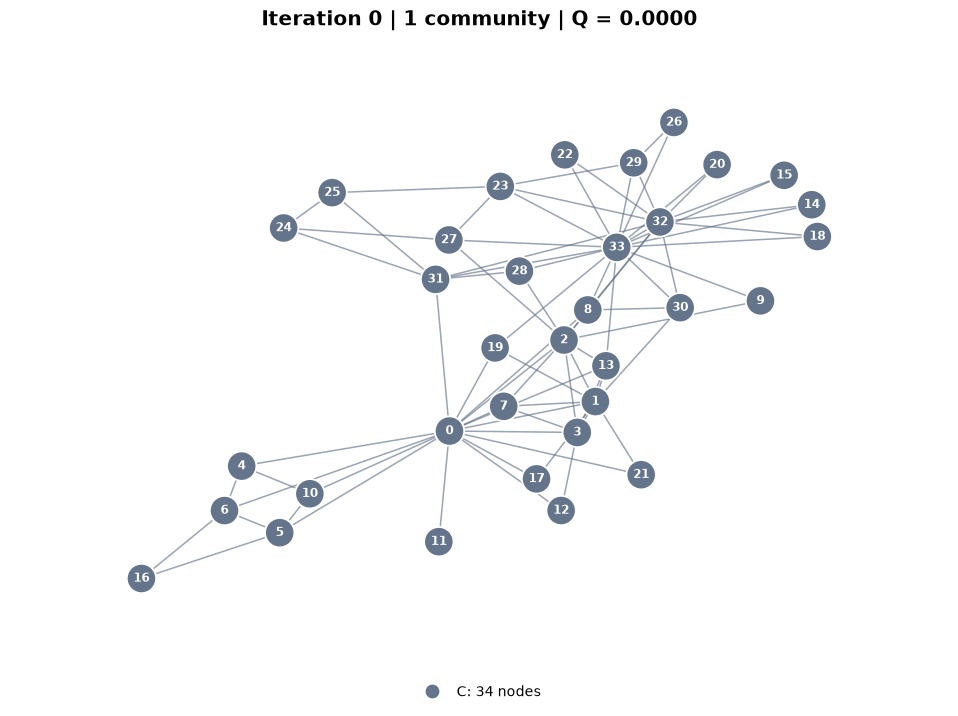

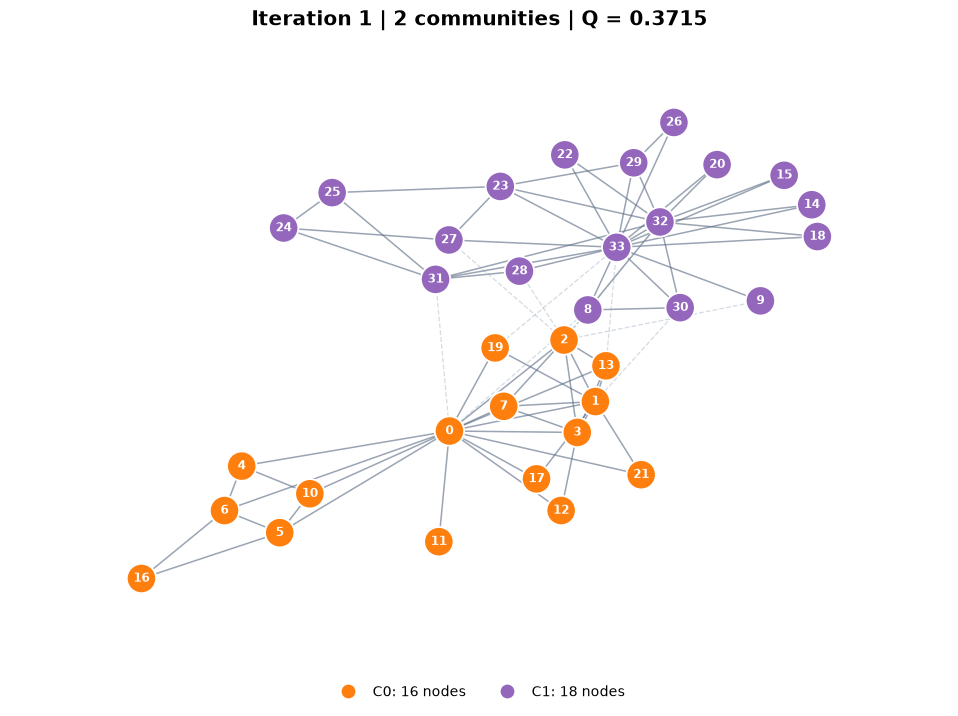

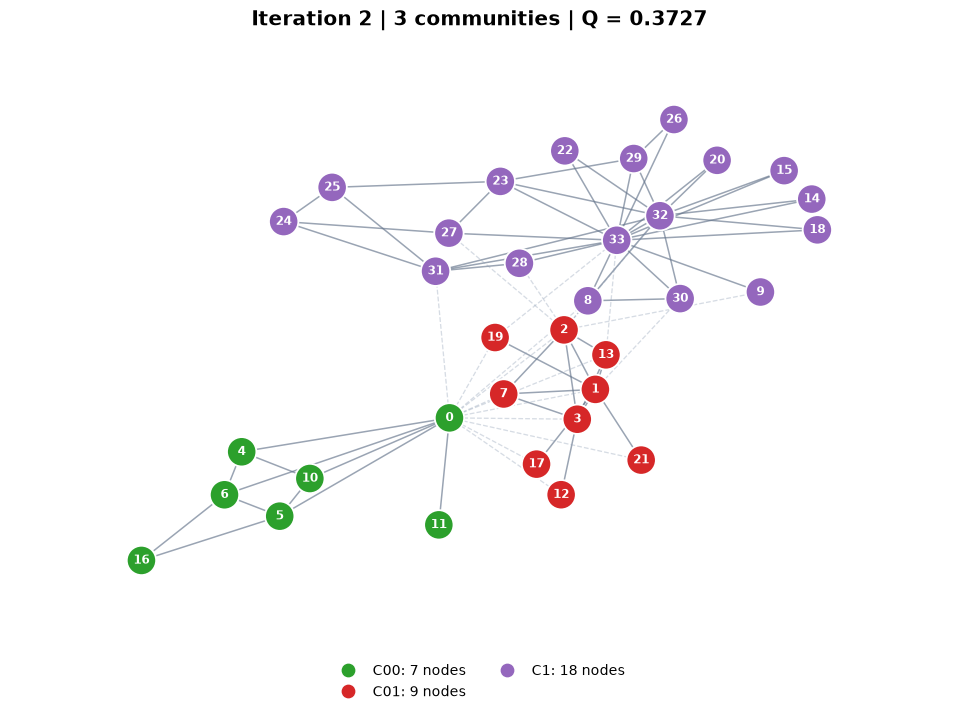

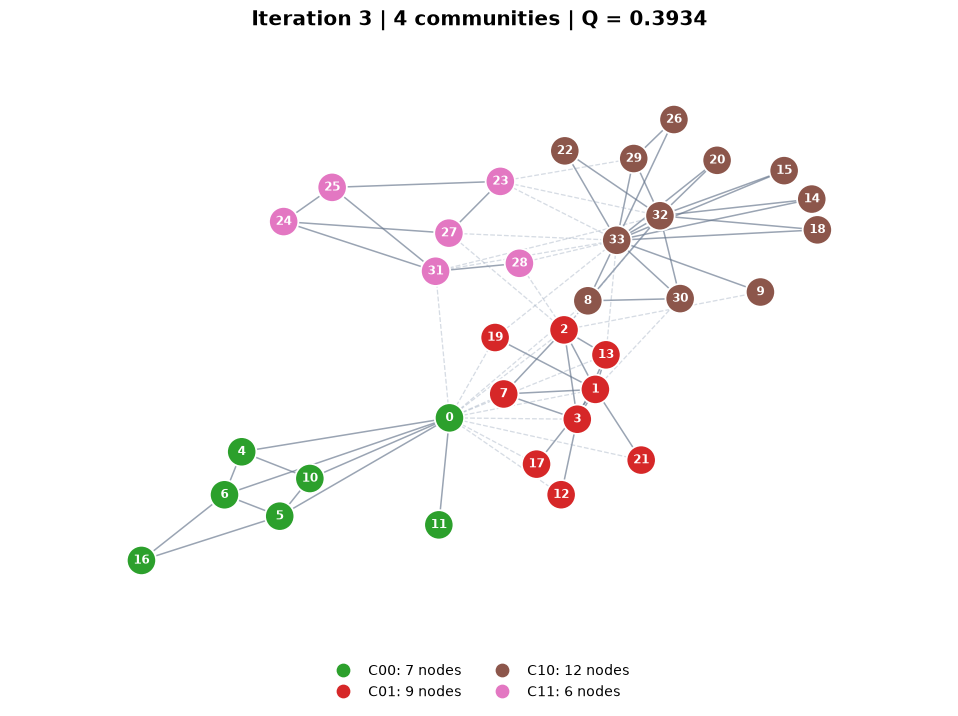

In [7]:
all_community_ids = sorted({key for state in history for key in state["partition"]})
community_palette = plt.get_cmap("tab10")
COMMUNITY_COLORS = {key: community_palette(index) for index, key in enumerate(all_community_ids)}
COMMUNITY_COLORS["C"] = "#64748b"

def draw_partition(state, ax):
    membership = {node: key for key, group in state["partition"].items() for node in group}
    inside = [(u, v) for u, v in G.edges() if membership[u] == membership[v]]
    outside = [(u, v) for u, v in G.edges() if membership[u] != membership[v]]
    nx.draw_networkx_edges(G, POSITIONS, edgelist=inside, ax=ax,
                           edge_color="#64748b", width=1.0, alpha=0.65)
    nx.draw_networkx_edges(G, POSITIONS, edgelist=outside, ax=ax,
                           edge_color="#94a3b8", width=0.85, alpha=0.38, style="dashed")
    nx.draw_networkx_nodes(G, POSITIONS, nodelist=NODES, ax=ax,
        node_color=[COMMUNITY_COLORS[membership[node]] for node in NODES],
        node_size=370, edgecolors="white", linewidths=1.2)
    nx.draw_networkx_labels(G, POSITIONS, ax=ax, font_size=8,
                            font_color="white", font_weight="bold")
    handles = [Line2D([], [], marker="o", linestyle="", markersize=8,
        color=COMMUNITY_COLORS[key], label=f"{key}: {len(group)} nodes")
        for key, group in state["partition"].items()]
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.01),
              ncol=2, frameon=False, fontsize=9)
    count = len(state["partition"])
    noun = "community" if count == 1 else "communities"
    ax.set_title(f"Iteration {state['iteration']} | {count} {noun} | Q = {state['modularity']:.4f}")
    ax.margins(0.13)
    ax.set_axis_off()

for state in history:
    fig, ax = plt.subplots(figsize=(8.6, 6.4), layout="constrained")
    draw_partition(state, ax)
    fig.savefig(FIGURES / f"community_iteration_{state['iteration']:02d}.png", bbox_inches="tight")
    display(fig)
    plt.close(fig)

fig, axes = plt.subplots(2, math.ceil(len(history) / 2),
    figsize=(15, 11), squeeze=False, layout="constrained")
for ax, state in zip(axes.flat, history):
    draw_partition(state, ax)
for ax in list(axes.flat)[len(history):]:
    ax.set_visible(False)
fig.savefig(FIGURES / "community_overview.png", bbox_inches="tight")
plt.close(fig)

## 6. Four metrics and the meaning of their evolution

Let $H$ be the graph supplied to a metric function, $N=|V(H)|$, and $d_i$ its degree
inside $H$. For the primary histories, $H=G[C]$ for the node's current community.

| Metric | Meaning and convention |
|---|---|
| Degree centrality | $d_i/(N-1)$ for $N>1$; fraction of other nodes directly adjacent |
| Betweenness | Fractional shortest-path contributions, **normalized**, endpoints excluded |
| Closeness | Reciprocal mean distance, using NetworkX's **Wasserman-Faust correction** for reachability |
| Clustering | $2T_i/[d_i(d_i-1)]$ for $d_i\ge2$; zero otherwise |

Unweighted paths are used. For a connected $H$, closeness is
$(N-1)/\sum_{j\ne i}d(i,j)$. If only $r$ other nodes are reachable, the corrected value
is $[r/(N-1)]\,[r/\sum_{j\text{ reachable}}d(i,j)]$, with zero for no reachable peers.
For a singleton, this notebook explicitly assigns zero to all four metrics (rather
than treating a node with no ties as maximally degree-central). No singleton occurs
in this Karate run. Betweenness normalization depends on the size of $H$ as well.

**Interpretation:** local degree centrality can rise even when raw degree falls because
the denominator shrinks. A larger local betweenness is not direct evidence of greater
whole-network influence. Clustering measures neighbor cohesion, not global importance.
See the official [degree](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.centrality.degree_centrality.html),
[betweenness](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.centrality.betweenness_centrality.html),
[closeness](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.centrality.closeness_centrality.html),
and [clustering](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.cluster.clustering.html) documentation.

In [8]:
METRIC_LABELS = {
    "degree_centrality": "Degree centrality",
    "betweenness_centrality": "Betweenness centrality",
    "closeness_centrality": "Closeness centrality",
    "clustering": "Clustering coefficient",
}

def compute_metrics(graph):
    values = {
        "degree_centrality": nx.degree_centrality(graph),
        "betweenness_centrality": nx.betweenness_centrality(
            graph, normalized=True, weight=None, endpoints=False),
        "closeness_centrality": nx.closeness_centrality(
            graph, distance=None, wf_improved=True),
        "clustering": nx.clustering(graph, weight=None),
    }
    if len(graph) == 1:
        node = next(iter(graph))
        for name in values:
            values[name][node] = 0.0
    return values

# Required structure: metric -> iteration -> node -> value.
metric_history = {name: {} for name in METRIC_LABELS}
global_metric_history = {name: {} for name in METRIC_LABELS}
metric_rows = []
global_rows = []
for state in history:
    iteration = state["iteration"]
    local_values = {name: {} for name in METRIC_LABELS}
    for community, group in state["partition"].items():
        subgraph = G.subgraph(group)
        values = compute_metrics(subgraph)
        for name in METRIC_LABELS:
            local_values[name].update(values[name])
        for node in group:
            metric_rows.append({
                "iteration": iteration, "node": node, "community": community,
                "community_size": len(group), "degree_in_community": subgraph.degree(node),
                "triangles_in_community": nx.triangles(subgraph, node),
                "reachable_other_nodes": len(nx.single_source_shortest_path_length(subgraph, node)) - 1,
                **{name: values[name][node] for name in METRIC_LABELS},
            })
    global_values = compute_metrics(G)  # Recompute as the unchanged-graph control.
    for name in METRIC_LABELS:
        metric_history[name][iteration] = dict(sorted(local_values[name].items()))
        global_metric_history[name][iteration] = dict(sorted(global_values[name].items()))
    for node in NODES:
        global_rows.append({"iteration": iteration, "node": node,
                            **{name: global_values[name][node] for name in METRIC_LABELS}})

metrics = pd.DataFrame(metric_rows).sort_values(["iteration", "node"]).reset_index(drop=True)
global_metrics = pd.DataFrame(global_rows).sort_values(["iteration", "node"]).reset_index(drop=True)
for name in METRIC_LABELS:
    for iteration in range(len(history)):
        assert set(metric_history[name][iteration]) == set(NODES)
        assert np.isfinite(list(metric_history[name][iteration].values())).all()
        assert all(np.isclose(global_metric_history[name][iteration][node],
                              global_metric_history[name][0][node]) for node in NODES)
assert metrics.shape[0] == len(NODES) * len(history)
assert np.isfinite(metrics[list(METRIC_LABELS)].to_numpy()).all()
assert np.allclose(metrics.loc[metrics.iteration == 0, list(METRIC_LABELS)],
                   global_metrics.loc[global_metrics.iteration == 0, list(METRIC_LABELS)])
print(f"Recorded {len(metrics)} node-iteration rows in each scope; all 34 nodes appear at every step.")
print("Final within-community metrics:")
display(metrics.loc[metrics.iteration == len(history) - 1].round(4))

Recorded 136 node-iteration rows in each scope; all 34 nodes appear at every step.
Final within-community metrics:


,iteration,node,community,community_size,degree_in_community,triangles_in_community,reachable_other_nodes,degree_centrality,betweenness_centrality,closeness_centrality,clustering
102,3,0,C00,7,5,4,6,0.8333,0.3778,0.8571,0.4000
103,3,1,C01,9,7,5,8,0.8750,0.6548,0.8889,0.2381
104,3,2,C01,9,4,5,8,0.5000,0.0119,0.6667,0.8333
105,3,3,C01,9,5,5,8,0.6250,0.2619,0.7273,0.5000
106,3,4,C00,7,3,2,6,0.5000,0.0222,0.6667,0.6667
107,3,5,C00,7,4,3,6,0.6667,0.1556,0.7500,0.5000
108,3,6,C00,7,4,3,6,0.6667,0.1556,0.7500,0.5000
109,3,7,C01,9,3,3,8,0.3750,0.0000,0.6154,1.0000
110,3,8,C10,12,3,3,11,0.2727,0.0000,0.5789,1.0000
111,3,9,C10,12,1,0,11,0.0909,0.0000,0.5238,0.0000


## 7. Metric evolution for every node

Each figure covers one metric and all 34 nodes, divided into four readable panels.
Node IDs, colors, and line styles are consistent across the four figures. Iteration 0
is the full graph, so a jump afterward can reflect both loss of external connections
and a change in the local normalization denominator.

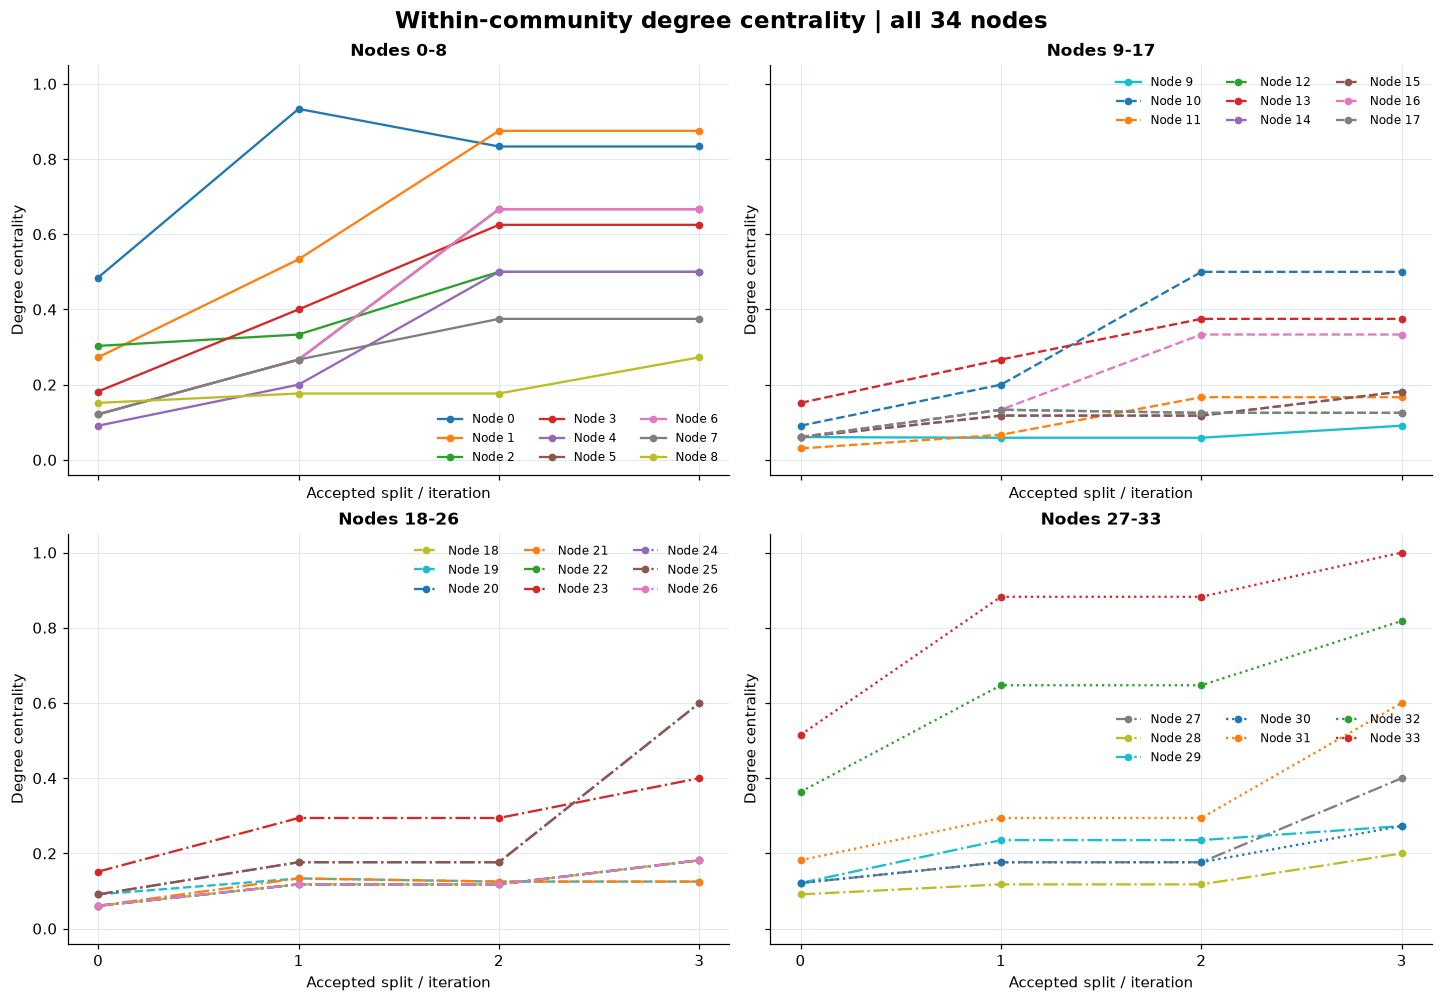

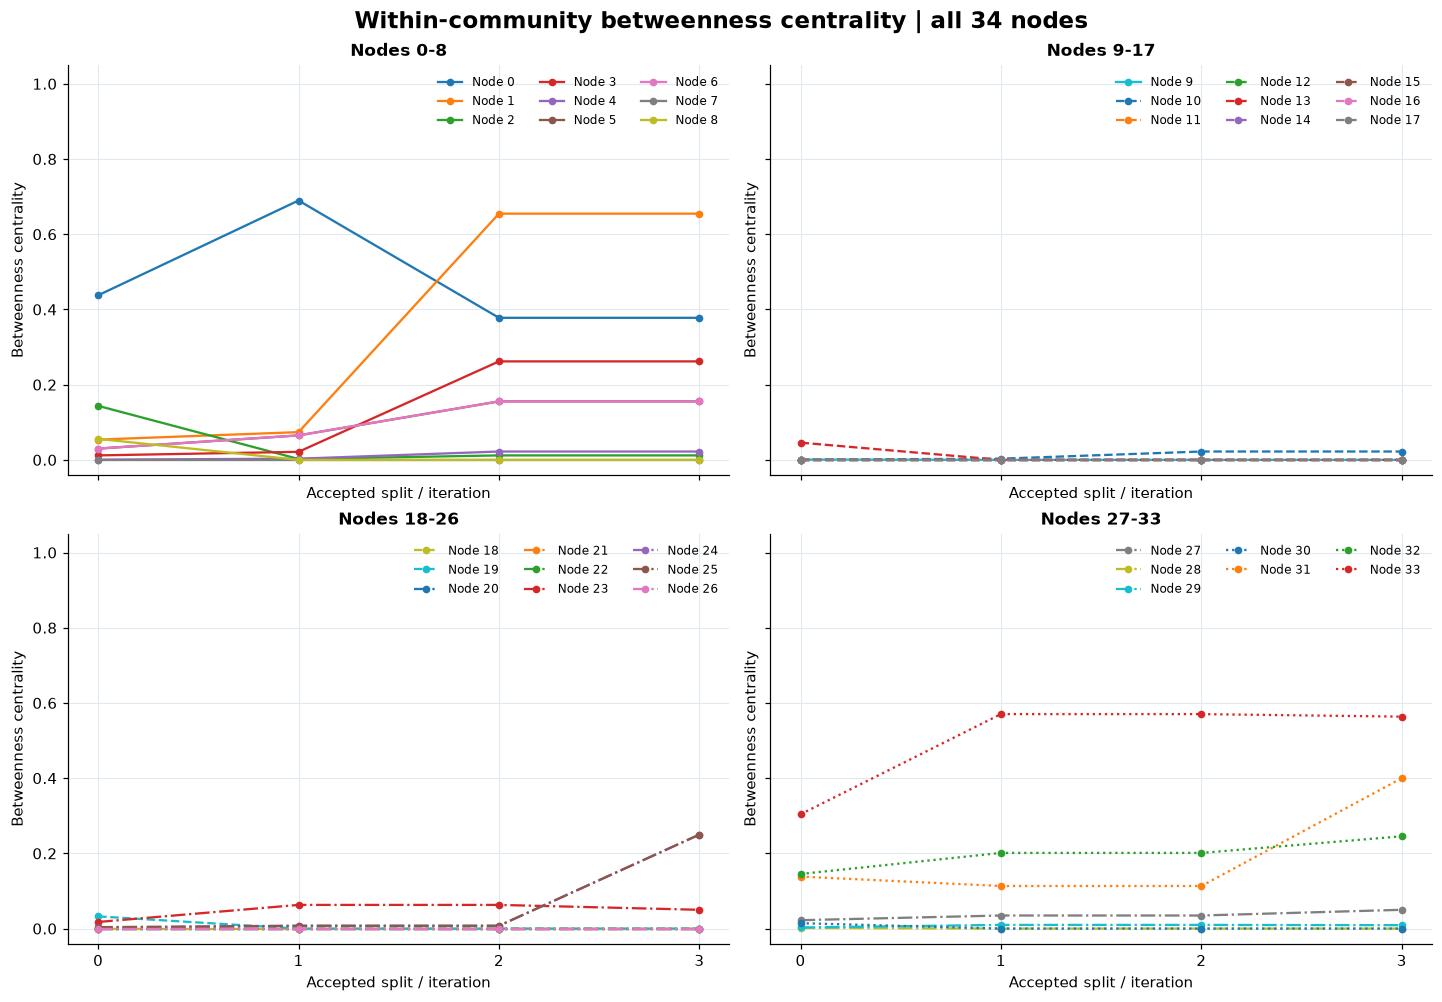

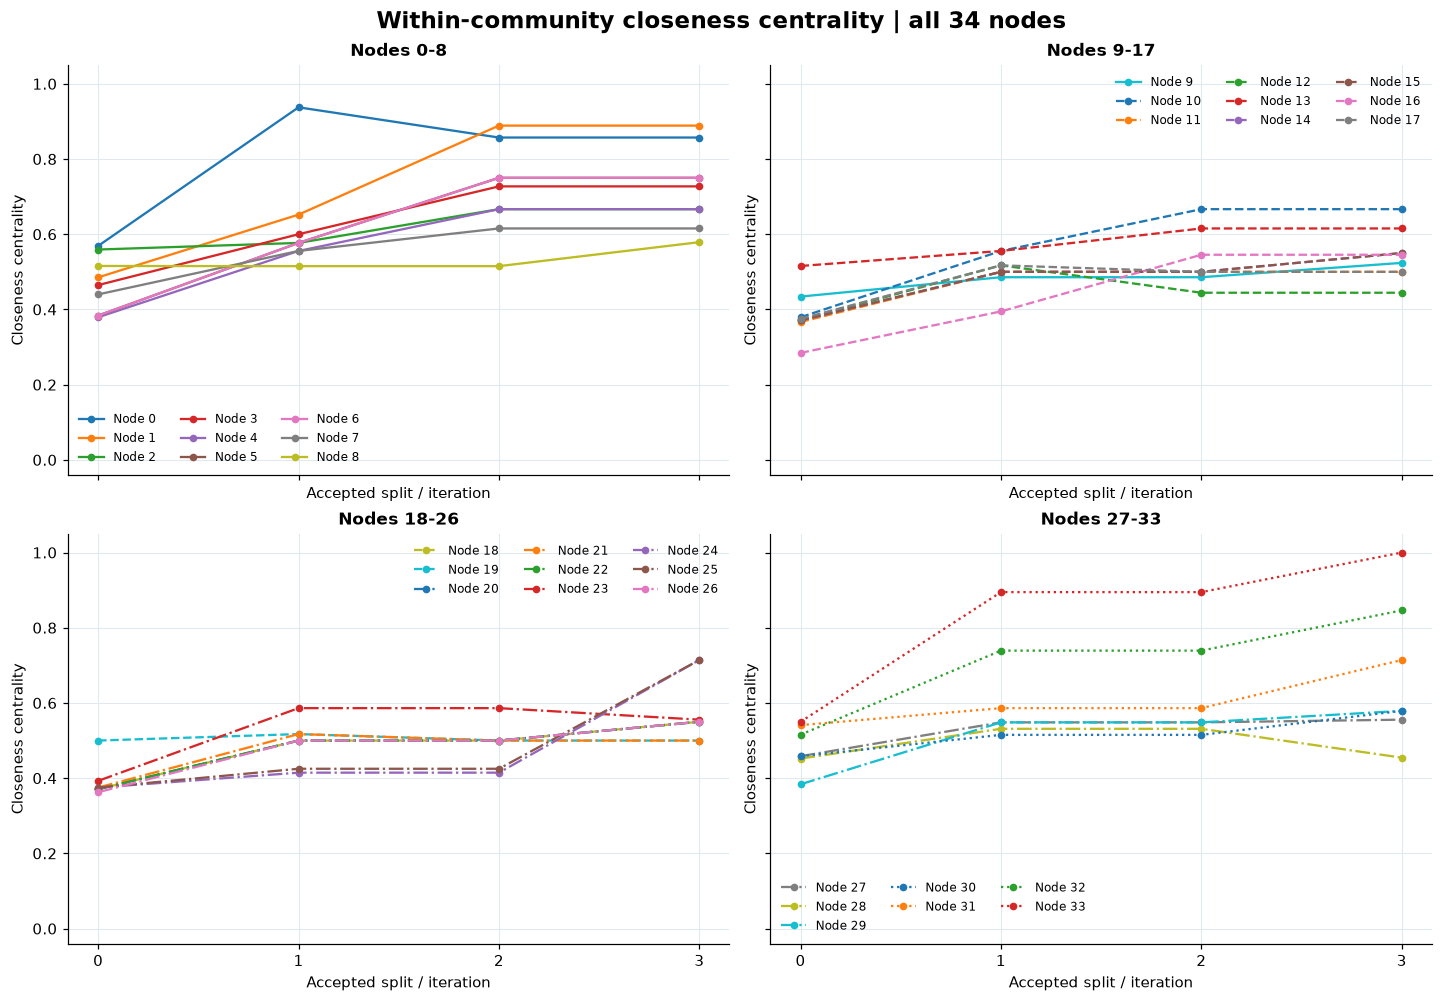

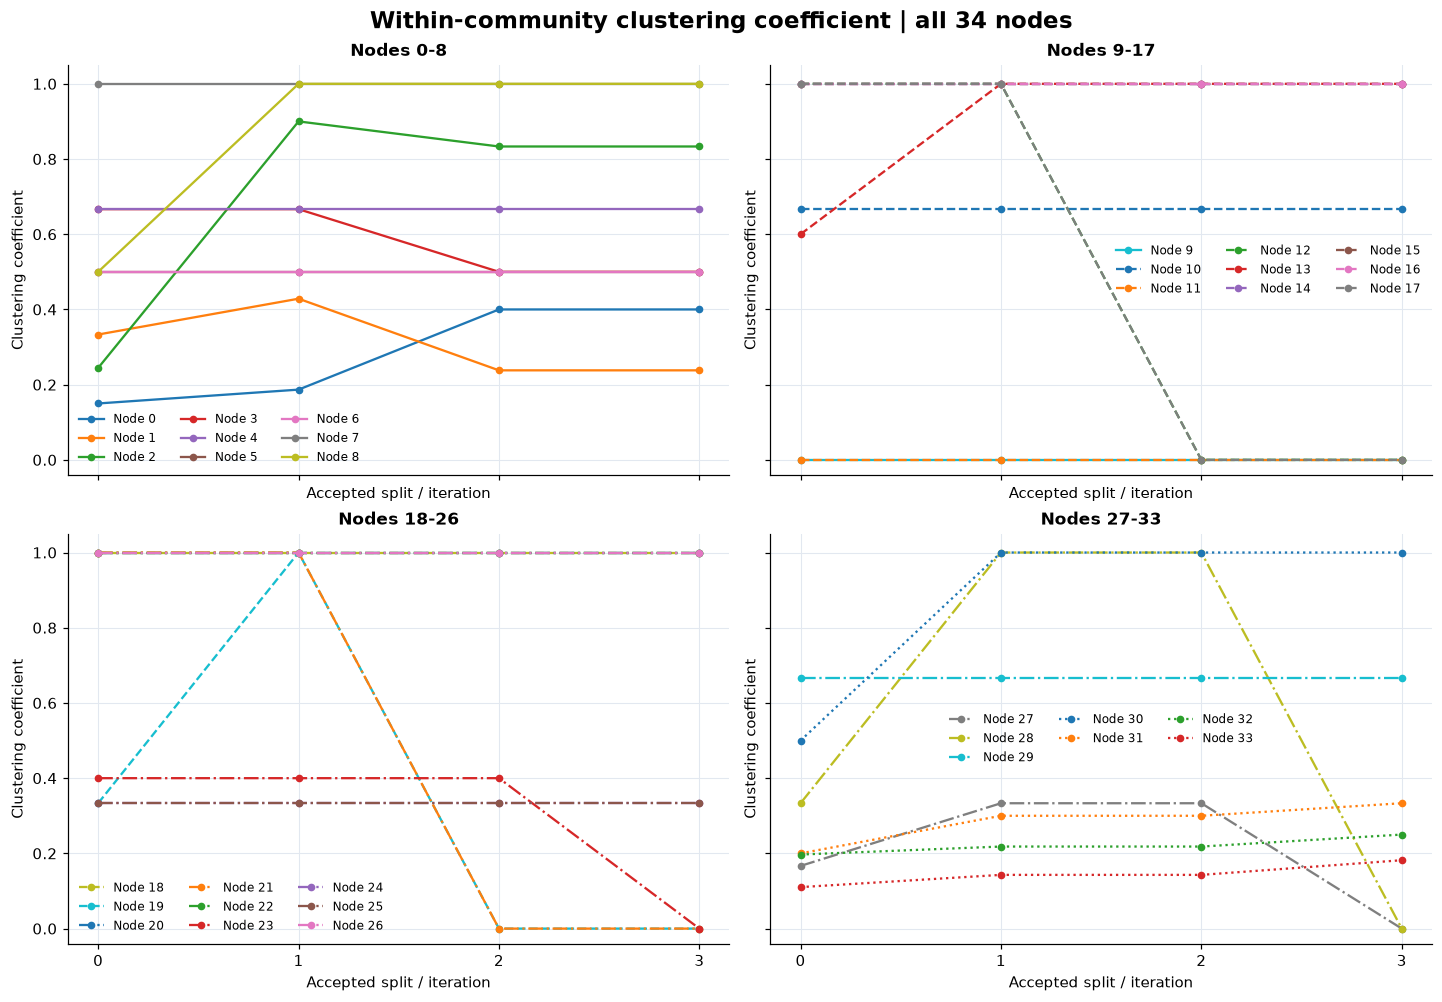

In [9]:
ITERATIONS = list(range(len(history)))
node_chunks = [NODES[start:start + 9] for start in range(0, len(NODES), 9)]
node_palette = plt.get_cmap("tab10")
line_styles = ["-", "--", "-.", ":"]
for name, label in METRIC_LABELS.items():
    fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True, sharey=True,
                             layout="constrained")
    for ax, chunk in zip(axes.flat, node_chunks):
        for node in chunk:
            ax.plot(ITERATIONS, [metric_history[name][step][node] for step in ITERATIONS],
                    color=node_palette(node % 10), linestyle=line_styles[(node // 10) % 4],
                    marker="o", markersize=4, linewidth=1.5, label=f"Node {node}")
        ax.set_title(f"Nodes {chunk[0]}-{chunk[-1]}", fontsize=11)
        ax.set_xticks(ITERATIONS)
        ax.set_ylim(-0.04, 1.05)
        ax.set_xlabel("Accepted split / iteration")
        ax.set_ylabel(label)
        ax.grid(True, color="#e2e8f0", linewidth=0.7)
        ax.legend(ncol=3, fontsize=8, frameon=False, loc="best")
    fig.suptitle(f"Within-community {label.lower()} | all 34 nodes", fontsize=15, fontweight="bold")
    fig.savefig(FIGURES / f"evolution_{name}.png", bbox_inches="tight")
    display(fig)
    plt.close(fig)

### Control: original-graph metrics remain unchanged

The four heatmaps below show every node at every iteration on the original graph.
Horizontal rows remain constant. This confirms that partitioning is an assignment
of labels, not the removal of friendships from the data used for detection.

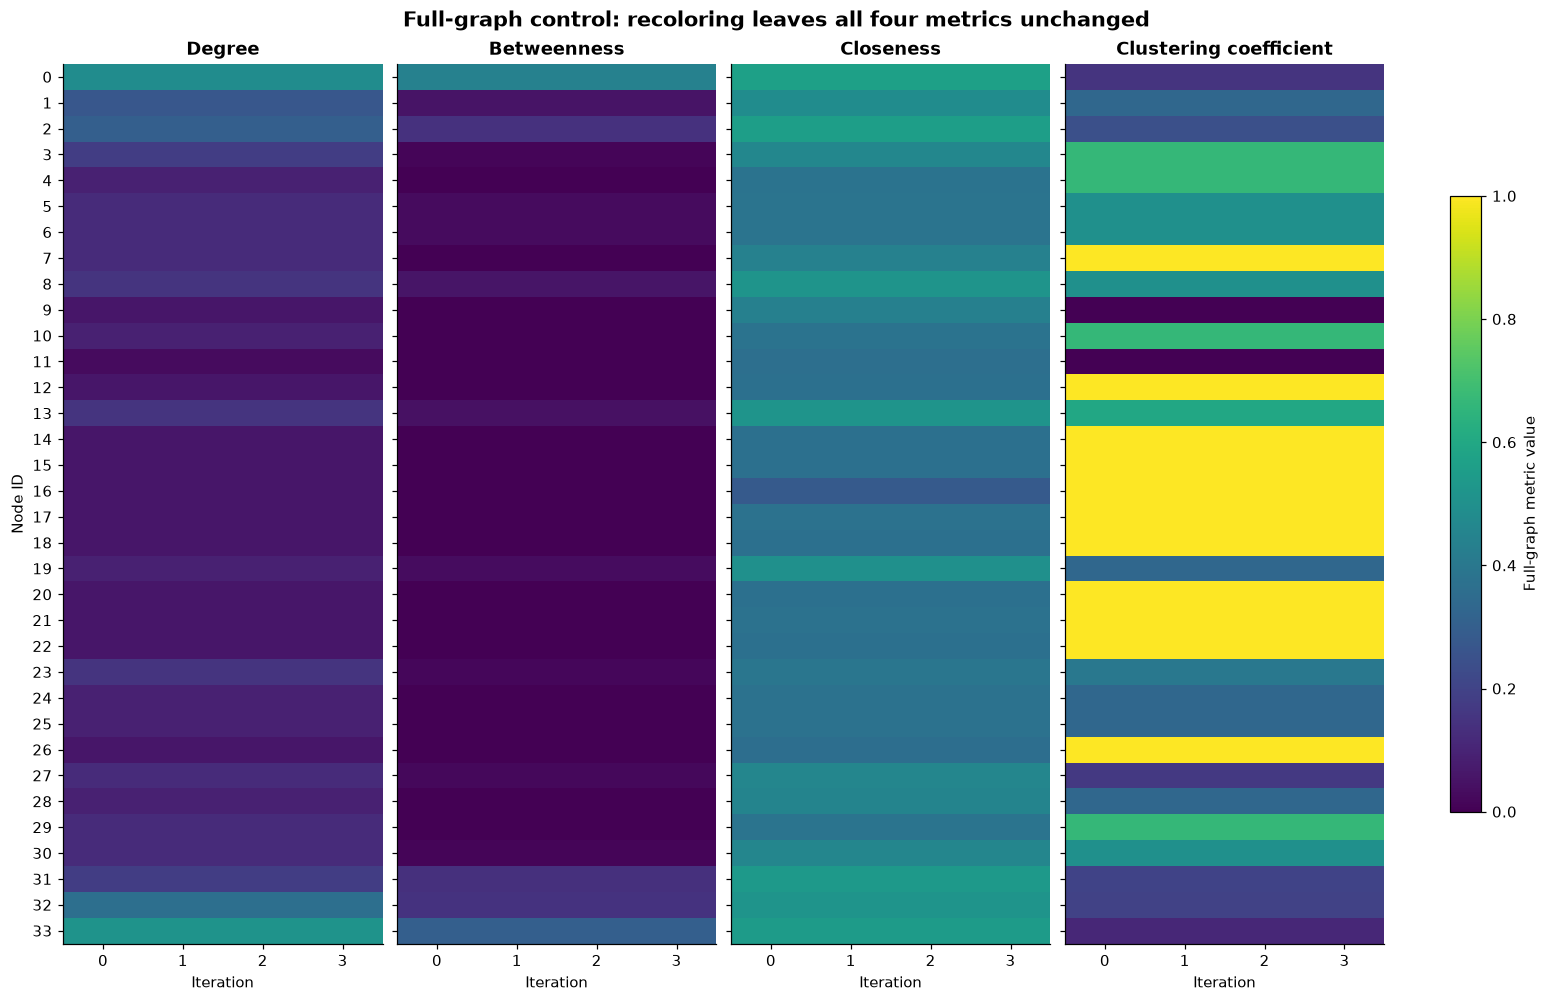

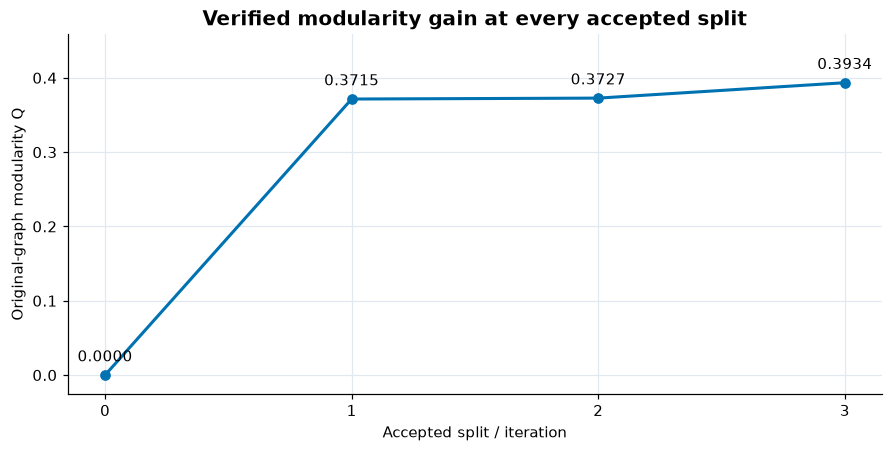

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(14, 9), sharey=True, layout="constrained")
for ax, (name, label) in zip(axes, METRIC_LABELS.items()):
    values = np.asarray([[global_metric_history[name][step][node] for step in ITERATIONS]
                         for node in NODES])
    image = ax.imshow(values, aspect="auto", cmap="viridis", vmin=0, vmax=1,
                       interpolation="nearest")
    ax.set_title(label.replace(" centrality", ""), fontsize=12)
    ax.set_xticks(ITERATIONS, labels=ITERATIONS)
    ax.set_yticks(range(len(NODES)), labels=NODES)
    ax.set_xlabel("Iteration")
axes[0].set_ylabel("Node ID")
fig.colorbar(image, ax=list(axes), label="Full-graph metric value", shrink=0.7)
fig.suptitle("Full-graph control: recoloring leaves all four metrics unchanged", fontsize=14, fontweight="bold")
fig.savefig(FIGURES / "global_metrics_control.png", bbox_inches="tight")
display(fig)
plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.plot(summary.iteration, summary.modularity, color="#0072b2", marker="o", linewidth=2)
for row in summary.itertuples():
    ax.annotate(f"{row.modularity:.4f}", (row.iteration, row.modularity),
                xytext=(0, 9), textcoords="offset points", ha="center", fontsize=10)
ax.set(xlabel="Accepted split / iteration", ylabel="Original-graph modularity Q",
       title="Verified modularity gain at every accepted split")
ax.set_xticks(ITERATIONS)
ax.set_ylim(-0.025, max(summary.modularity) + 0.065)
ax.grid(True, color="#e2e8f0")
fig.savefig(FIGURES / "modularity_progress.png", bbox_inches="tight")
display(fig)
plt.close(fig)

## 8. Results and discussion

The following tables and commentary are generated from the computed histories, rather
than copied from a reference result. Ranking is performed separately for each metric
and scope. Tied values are retained; node IDs only break ties when displaying a short list.

In [11]:
final_iteration = len(history) - 1
initial = metrics.loc[metrics.iteration == 0].set_index("node")
final = metrics.loc[metrics.iteration == final_iteration].set_index("node")
community_results = pd.DataFrame([{
    "community": key, "size": len(group), "nodes": ", ".join(map(str, group)),
    "internal_edges": G.subgraph(group).number_of_edges(),
    "connected": nx.is_connected(G.subgraph(group)),
} for key, group in final_partition.items()])
display(community_results)

ranking_rows = []
for state in history:
    step = state["iteration"]
    for name, label in METRIC_LABELS.items():
        values = metric_history[name][step]
        ordered = sorted(NODES, key=lambda node: (-values[node], node))
        ranking_rows.append({"iteration": step, "metric": label,
            "top_5_nodes": ", ".join(map(str, ordered[:5])),
            "top_5_values": ", ".join(f"{values[node]:.4f}" for node in ordered[:5])})
rankings = pd.DataFrame(ranking_rows)
display(rankings)

comparisons = []
for node in [0, 1, 31, 32, 33]:
    comparisons.append({"node": node,
        "global_degree": int(G.degree(node)),
        "final_local_degree": int(final.loc[node, "degree_in_community"]),
        "final_group_size": int(final.loc[node, "community_size"]),
        **{f"initial_{name}": initial.loc[node, name] for name in METRIC_LABELS},
        **{f"final_{name}": final.loc[node, name] for name in METRIC_LABELS}})
comparison = pd.DataFrame(comparisons)
display(comparison.round(4))

def show_value(node, name, stage):
    return f"{metric_history[name][stage][node]:.4f}"

rejected_positive = [row for row in attempts if not row["accepted"] and
                     row.get("leading_eigenvalue") is not None and
                     row["leading_eigenvalue"] > TOLERANCE and
                     row.get("candidate_gain") is not None]
rejection_text = ""
if rejected_positive:
    row = rejected_positive[0]
    rejection_text = (f"For community **{row['community']}**, the leading eigenvalue is "
                      f"**{row['leading_eigenvalue']:.6f}**, but its rounded proposal has "
                      f"**Delta Q = {row['candidate_gain']:.6f}**. It is correctly rejected. "
                      "This is direct evidence that a positive eigenvalue alone is insufficient.")

discussion = f"""
### Community structure

There are **{len(history)-1} accepted splits**, producing **{len(final_partition)} communities**
of sizes **{', '.join(str(len(group)) for group in final_partition.values())}**.
Original-graph modularity rises from **{history[0]['modularity']:.4f}** to
**{history[-1]['modularity']:.6f}**. The gain table shows the contribution of each split;
the algorithm never forces a target community count. Every final community in this run
is connected, as checked in the table above.

### Which nodes remain central?

Nodes **0 and 33** remain prominent local hubs. Their degree-centrality trajectories are
**{' -> '.join(show_value(0, 'degree_centrality', step) for step in ITERATIONS)}** and
**{' -> '.join(show_value(33, 'degree_centrality', step) for step in ITERATIONS)}**, respectively.
Their closeness values also stay high relative to their own communities. The complete
ranking table gives the evidence at every stage; prominence is assessed separately
for each metric rather than reduced to one universal notion of importance.

Node **1** becomes especially prominent within its final community: its normalized
betweenness changes from **{show_value(1, 'betweenness_centrality', 0)}** to
**{show_value(1, 'betweenness_centrality', final_iteration)}**. Node **31** has final local
betweenness **{show_value(31, 'betweenness_centrality', final_iteration)}**. These describe
brokerage among their local peers, not an increase in their original whole-club influence.
In the unchanged full graph, node 0 has the largest betweenness and node 33 the largest degree.

### Why do values change?

Node **0** has **{G.degree(0)}** neighbors in the full graph but only
**{int(final.loc[0, 'degree_in_community'])}** inside its final group of
**{int(final.loc[0, 'community_size'])}** nodes. Its normalized degree rises because the
comparison population shrinks. Node **33** similarly has **{G.degree(33)}** original
neighbors and **{int(final.loc[33, 'degree_in_community'])}** local neighbors, yet its final
local degree centrality is **{show_value(33, 'degree_centrality', final_iteration)}**.
Neither node acquired a new friendship in this analysis.

Closeness can increase when measured against a smaller set of nearby peers. Betweenness
changes because the relevant shortest paths and their normalization change. Node 0's
clustering moves from **{show_value(0, 'clustering', 0)}** to
**{show_value(0, 'clustering', final_iteration)}**, reflecting a different ratio of realized
triangles to possible neighbor pairs. A node can have clustering 1 while having few
neighbors, so this should not be confused with being a global hub.

### Stopping and limitations

{rejection_text}

This is a sign-rounded spectral heuristic without vertex-move fine-tuning. The final
partition is not claimed to be the globally optimal modularity partition. Three final
groups have no positive adjusted eigenvalue within tolerance; the remaining group's
leading sign proposal fails the gain test. Intermediate histories depend on the stated
depth-first traversal. Local normalized values from different-sized groups require care;
the full-graph control stays constant and supplies the global context.
"""
display(Markdown(discussion))

,community,size,nodes,internal_edges,connected
0,C00,7,"0, 4, 5, 6, 10, 11, 16",11,True
1,C01,9,"1, 2, 3, 7, 12, 13, 17, 19, 21",13,True
2,C10,12,"8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33",21,True
3,C11,6,"23, 24, 25, 27, 28, 31",7,True


,iteration,metric,top_5_nodes,top_5_values
0,0,Degree centrality,"33, 0, 32, 2, 1","0.5152, 0.4848, 0.3636, 0.3030, 0.2727"
1,0,Betweenness centrality,"0, 33, 32, 2, 31","0.4376, 0.3041, 0.1452, 0.1437, 0.1383"
2,0,Closeness centrality,"0, 2, 33, 31, 8","0.5690, 0.5593, 0.5500, 0.5410, 0.5156"
3,0,Clustering coefficient,"7, 12, 14, 15, 16","1.0000, 1.0000, 1.0000, 1.0000, 1.0000"
4,1,Degree centrality,"0, 33, 32, 1, 3","0.9333, 0.8824, 0.6471, 0.5333, 0.4000"
5,1,Betweenness centrality,"0, 33, 32, 31, 1","0.6897, 0.5703, 0.2012, 0.1132, 0.0738"
6,1,Closeness centrality,"0, 33, 32, 1, 3","0.9375, 0.8947, 0.7391, 0.6522, 0.6000"
7,1,Clustering coefficient,"7, 8, 12, 13, 14","1.0000, 1.0000, 1.0000, 1.0000, 1.0000"
8,2,Degree centrality,"33, 1, 0, 5, 6","0.8824, 0.8750, 0.8333, 0.6667, 0.6667"
9,2,Betweenness centrality,"1, 33, 0, 3, 32","0.6548, 0.5703, 0.3778, 0.2619, 0.2012"


,node,global_degree,final_local_degree,final_group_size,initial_degree_centrality,initial_betweenness_centrality,initial_closeness_centrality,initial_clustering,final_degree_centrality,final_betweenness_centrality,final_closeness_centrality,final_clustering
0,0,16,5,7,0.4848,0.4376,0.5690,0.1500,0.8333,0.3778,0.8571,0.4000
1,1,9,7,9,0.2727,0.0539,0.4853,0.3333,0.8750,0.6548,0.8889,0.2381
2,31,6,3,6,0.1818,0.1383,0.5410,0.2000,0.6000,0.4000,0.7143,0.3333
3,32,12,9,12,0.3636,0.1452,0.5156,0.1970,0.8182,0.2455,0.8462,0.2500
4,33,17,11,12,0.5152,0.3041,0.5500,0.1103,1.0000,0.5636,1.0000,0.1818



### Community structure

There are **3 accepted splits**, producing **4 communities**
of sizes **7, 9, 12, 6**.
Original-graph modularity rises from **0.0000** to
**0.393409**. The gain table shows the contribution of each split;
the algorithm never forces a target community count. Every final community in this run
is connected, as checked in the table above.

### Which nodes remain central?

Nodes **0 and 33** remain prominent local hubs. Their degree-centrality trajectories are
**0.4848 -> 0.9333 -> 0.8333 -> 0.8333** and
**0.5152 -> 0.8824 -> 0.8824 -> 1.0000**, respectively.
Their closeness values also stay high relative to their own communities. The complete
ranking table gives the evidence at every stage; prominence is assessed separately
for each metric rather than reduced to one universal notion of importance.

Node **1** becomes especially prominent within its final community: its normalized
betweenness changes from **0.0539** to
**0.6548**. Node **31** has final local
betweenness **0.4000**. These describe
brokerage among their local peers, not an increase in their original whole-club influence.
In the unchanged full graph, node 0 has the largest betweenness and node 33 the largest degree.

### Why do values change?

Node **0** has **16** neighbors in the full graph but only
**5** inside its final group of
**7** nodes. Its normalized degree rises because the
comparison population shrinks. Node **33** similarly has **17** original
neighbors and **11** local neighbors, yet its final
local degree centrality is **1.0000**.
Neither node acquired a new friendship in this analysis.

Closeness can increase when measured against a smaller set of nearby peers. Betweenness
changes because the relevant shortest paths and their normalization change. Node 0's
clustering moves from **0.1500** to
**0.4000**, reflecting a different ratio of realized
triangles to possible neighbor pairs. A node can have clustering 1 while having few
neighbors, so this should not be confused with being a global hub.

### Stopping and limitations

For community **C01**, the leading eigenvalue is **0.060191**, but its rounded proposal has **Delta Q = -0.015779**. It is correctly rejected. This is direct evidence that a positive eigenvalue alone is insufficient.

This is a sign-rounded spectral heuristic without vertex-move fine-tuning. The final
partition is not claimed to be the globally optimal modularity partition. Three final
groups have no positive adjusted eigenvalue within tolerance; the remaining group's
leading sign proposal fails the gain test. Intermediate histories depend on the stated
depth-first traversal. Local normalized values from different-sized groups require care;
the full-graph control stays constant and supplies the global context.


## 9. Optional comparison with the historical two-faction outcome

The first bisection can be compared with the recorded two factions, allowing exchange
of the arbitrary group names. This comparison does not guide the algorithm. The final
multi-community partition need not equal the historical binary split, so a contingency
table is more appropriate than forcing the final communities into two labels.

In [12]:
faction_rows = pd.DataFrame([{
    "node": node, "historical_faction": G.nodes[node]["club"],
    "first_community": first_membership[node],
    "final_community": next(key for key, group in final_partition.items() if node in group),
} for node in NODES])
display(pd.crosstab(faction_rows.final_community, faction_rows.historical_faction))
if len(first_partition) == 2:
    child_keys = list(first_partition)
    faction_names = sorted(faction_rows.historical_faction.unique())
    agreement = []
    for ordering in [faction_names, faction_names[::-1]]:
        mapping = dict(zip(child_keys, ordering))
        agreement.append(sum(mapping[first_membership[node]] == G.nodes[node]["club"] for node in NODES))
    print(f"First bisection agreement under best label exchange: {max(agreement)}/{len(NODES)} nodes.")

historical_faction,Mr. Hi,Officer
final_community,,
C00,7,0
C01,9,0
C10,1,11
C11,0,6


First bisection agreement under best label exchange: 33/34 nodes.


## 10. Study notes for the conceptual exam

1. **Why not just minimize a cut?** With unconstrained group sizes, isolating a small
   low-degree group can produce a small cut without revealing meaningful communities.
   Modularity instead compares internal edges with a degree-based baseline.
2. **What is $B_{ij}$?** An observed-minus-baseline pair contribution. Its sign is a
   preference, not a community label; conflicting preferences require tradeoffs.
3. **Why is $B$ symmetric?** Both $A$ and $kk^\top$ are symmetric for this graph.
   Therefore its eigenvalues are real and an orthonormal eigenbasis exists.
4. **Why do the rows sum to zero?**
   $\sum_jB_{ij}=k_i-k_i(\sum_jk_j)/(2m)=0$. Hence $B\mathbf1=0$.
5. **Why is the unsplit modularity zero?** With $s=\mathbf1$,
   $Q=\mathbf1^\top B\mathbf1/(4m)=0$.
6. **Why a leading eigenvector?** The Rayleigh quotient's largest value occurs in that
   direction after relaxing the binary constraint. Taking signs produces a candidate,
   not a proof of the best discrete assignment.
7. **Why does reversing every sign change nothing?** It exchanges group names and
   $(-s)^\top B(-s)=s^\top Bs$.
8. **Why the adjusted recursive matrix?** It subtracts the pre-split contribution of
   the parent. The original degrees and edge count keep the null model consistent.
9. **When should recursion stop?** No positive adjusted eigenvalue certifies no
   positive gain. A positive eigenvalue still requires a positive actual rounded gain.
   A rejected heuristic proposal is not a proof about all binary proposals.
10. **Hub, broker, reach, cohesion?** These correspond to degree, betweenness,
    closeness, and clustering. High clustering does not imply high global centrality.
11. **Why do local metrics change?** Their graph, path population, and possibly their
    normalization denominator change. Recoloring the original graph alone changes none.
12. **What happened in this experiment?** Use the computed split/gain table, final
    community table, and node comparisons above. Explain the positive-eigenvalue
    rejection and the raw-degree versus normalized-degree example in your own words.

**Practice a five-mark answer:** describe the null model, write $B$ and $Q$, explain
leading-eigenvector signs, state the gain check and recursive stopping, then distinguish
one local metric change from an unchanged whole-graph metric. This is preparation,
not a prediction of the exact examination question.

## 11. References

1. Newman, M. E. J. (2006). **Modularity and community structure in networks.**
   *Proceedings of the National Academy of Sciences*, **103**(23), 8577-8582.
   [doi:10.1073/pnas.0601602103](https://doi.org/10.1073/pnas.0601602103).
   [Author preprint](https://arxiv.org/abs/physics/0602124).
2. Zachary, W. W. (1977). **An Information Flow Model for Conflict and Fission in
   Small Groups.** *Journal of Anthropological Research*, **33**(4), 452-473.
   [doi:10.1086/jar.33.4.3629752](https://doi.org/10.1086/jar.33.4.3629752).
3. NetworkX documentation: [Karate graph](https://networkx.org/documentation/stable/reference/generated/networkx.generators.social.karate_club_graph.html),
   [modularity](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.community.quality.modularity.html),
   and the four metric references linked in Section 6. Exact package versions are
   printed in Section 1 and pinned in `requirements.txt`.
4. DSC212 course assignment handout, **Modularity on the Karate Club Graph**, and
   the instructor's accompanying assignment announcement. The handout defines the
   required deliverables; the recursive formula clarification is explained in Section 3.

## 12. Export results and verify deliverables

All files below are regenerated by running the notebook. CSV tables expose every
node-iteration value; JSON files preserve the full partition and metric histories.
In JSON, integer dictionary keys are represented as strings by the file format.
The notebook itself is the primary submission and already contains its rendered outputs.

In [13]:
summary.to_csv(TABLES / "split_summary.csv", index=False)
attempt_table.to_csv(TABLES / "split_attempts.csv", index=False)
community_results.to_csv(TABLES / "final_communities.csv", index=False)
metrics.to_csv(TABLES / "metrics_within_communities.csv", index=False)
global_metrics.to_csv(TABLES / "metrics_full_graph.csv", index=False)
rankings.to_csv(TABLES / "top_nodes_by_iteration.csv", index=False)
comparison.to_csv(TABLES / "selected_node_comparisons.csv", index=False)
faction_rows.to_csv(TABLES / "historical_faction_comparison.csv", index=False)
first_split_details.to_csv(TABLES / "first_split_eigenvector.csv", index=False)

def save_json(name, value):
    (ARTIFACTS / name).write_text(json.dumps(value, indent=2, allow_nan=False) + "\n", encoding="utf-8")

save_json("partition_history.json", history)
save_json("split_attempts.json", attempts)
save_json("metric_history_within_communities.json", metric_history)
save_json("metric_history_full_graph.json", global_metric_history)
save_json("layout_positions.json", {node: position.tolist() for node, position in POSITIONS.items()})
save_json("run_metadata.json", {
    "dataset": "NetworkX Zachary Karate Club", "weighted": False,
    "node_ids": list(NODES), "nodes": len(G), "edges": G.number_of_edges(),
    "layout_seed": SEED, "minimum_node_spacing": MIN_NODE_SPACING, "tolerance": TOLERANCE,
    "iteration_definition": "one accepted depth-first split",
    "recursive_matrix": "B[C,C] - diag(B[C,C] @ ones)",
    "primary_metric_scope": "each node's current community induced subgraph",
    "control_metric_scope": "unchanged original graph",
    "versions": versions, "python": platform.python_version(),
    "final_community_sizes": [len(group) for group in final_partition.values()],
    "final_modularity": history[-1]["modularity"],
})

validation = {
    "all_nodes_once_per_partition": True,
    "all_accepted_gains_positive": True,
    "matrix_scores_match_networkx": True,
    "recursive_gain_identity_cases": gain_cases,
    "original_graph_unchanged": True,
    "all_four_metrics_all_nodes_all_iterations": True,
    "global_metrics_constant": True,
    "metric_rows_per_scope": len(metrics),
    "saved_community_snapshots": len(list(FIGURES.glob("community_iteration_*.png"))),
    "metric_evolution_figures": len(list(FIGURES.glob("evolution_*.png"))),
}
assert validation["saved_community_snapshots"] == len(history)
assert validation["metric_evolution_figures"] == 4
save_json("validation.json", validation)
print("All validation checks passed.")
print(f"Exported {len(list(TABLES.glob('*.csv')))} CSV tables and {len(list(FIGURES.glob('*.png')))} figures.")
display(pd.DataFrame(validation.items(), columns=["Check", "Result"]))

All validation checks passed.
Exported 9 CSV tables and 11 figures.


,Check,Result
0,all_nodes_once_per_partition,True
1,all_accepted_gains_positive,True
2,matrix_scores_match_networkx,True
3,recursive_gain_identity_cases,8
4,original_graph_unchanged,True
5,all_four_metrics_all_nodes_all_iterations,True
6,global_metrics_constant,True
7,metric_rows_per_scope,136
8,saved_community_snapshots,4
9,metric_evolution_figures,4
